# 01 — EDA: HCRL Car Hacking Challenge 2020 (prelim_train only)

**Scope:** only the `Pre_train_*` files (subset `prelim_train`). `Pre_submit_*` and `Fin_*` are future
held-out test sets, so their distributions must never shape design choices (that would leak test information).
Integrity checks on *all* files live in `reports/cleaning_report.md` (all checks OK, nothing dropped).

**Goal:** understand the data well enough to pick a window size and design per-frame features in Phase 3.
No features or models here.

Sections: 1. Class/SubClass distribution · 2. Top IDs · 3. Per-ID inter-arrival time (window size) ·
4. S vs D comparison · 5. Takeaways

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from src.load import BYTE_COLS, SUBCLASS_CATS, load_processed

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Fixed colors per entity (never re-assigned by rank). Validated categorical order: blue, orange, aqua, yellow, magenta.
SUBCLASS_COLORS = {"Normal": "#2a78d6", "Flooding": "#eb6834", "Spoofing": "#1baf7a",
                   "Replay": "#eda100", "Fuzzing": "#e87ba4"}
ATTACKS = ["Flooding", "Spoofing", "Replay", "Fuzzing"]
MODE_COLORS = {"S": "#2a78d6", "D": "#eb6834"}
MODE_NAME = {"S": "S (stationary)", "D": "D (driving)"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
hexid = lambda i: f"0x{int(i):03X}"

In [2]:
df = load_processed(subset="prelim_train")
assert set(df["subset"].unique()) == {"prelim_train"}, "EDA must only see prelim_train files"
df = df.sort_values(["source_file", "row_idx"], kind="stable").reset_index(drop=True)
print(f"{len(df):,} frames from {df['source_file'].nunique()} files:", list(df["source_file"].cat.categories))
print(f"memory: {df.memory_usage(deep=True).sum() / 2**20:.0f} MB")

# Per-ID inter-arrival, past frames only (diff to the previous frame of the same ID in the same file).
# dt_same_id      : full stream (what a detector would see, attacks included)
# dt_normal       : Normal-only stream (the vehicle's natural period, injected frames removed)
df["dt_same_id"] = df.groupby(["source_file", "arb_id"], observed=True)["timestamp"].diff()
df["dt_bus"] = df.groupby("source_file", observed=True)["timestamp"].diff()  # to previous frame of any ID
normal = df[df["class"] == "Normal"].copy()
normal["dt_normal"] = normal.groupby(["source_file", "arb_id"], observed=True)["timestamp"].diff()

3,672,151 frames from 6 files: ['Pre_train_D_0', 'Pre_train_D_1', 'Pre_train_D_2', 'Pre_train_S_0', 'Pre_train_S_1', 'Pre_train_S_2']
memory: 137 MB


## 1. Class / SubClass distribution per file
Why: tells us how imbalanced the problem is per file and whether every attack type exists in both modes —
this constrains how a file-level train/val split can be made in Phase 3.

In [3]:
counts = pd.crosstab(df["source_file"], df["subclass"]).reindex(columns=SUBCLASS_CATS)
counts["total"] = counts.sum(axis=1)
counts["attack_%"] = (100 * (1 - counts["Normal"] / counts["total"])).round(2)
dur = df.groupby("source_file", observed=True)["timestamp"].agg(lambda t: t.max() - t.min())
counts["duration_s"] = dur.round(1)
counts.loc["ALL"] = counts.drop(columns=["attack_%", "duration_s"]).sum().tolist() + [
    round(100 * (1 - counts["Normal"].sum() / counts["total"].sum()), 2), round(dur.sum(), 1)]
counts

subclass,Normal,Flooding,Spoofing,Replay,Fuzzing,total,attack_%,duration_s
source_file,,,,,,,,
Pre_train_D_0,179346.0,0.0,0.0,0.0,0.0,179346.0,0.00,74.7
Pre_train_D_1,733752.0,38521.0,988.0,10509.0,22620.0,806390.0,9.01,304.9
Pre_train_D_2,811532.0,38852.0,2891.0,13266.0,22854.0,889395.0,8.75,337.4
Pre_train_S_0,180686.0,0.0,0.0,0.0,0.0,180686.0,0.00,75.3
Pre_train_S_1,727749.0,38151.0,988.0,10525.0,21879.0,799292.0,8.95,302.9
Pre_train_S_2,739678.0,38656.0,2889.0,13293.0,22526.0,817042.0,9.47,308.4
ALL,3372743.0,154180.0,7756.0,47593.0,89879.0,3672151.0,8.15,1403.5


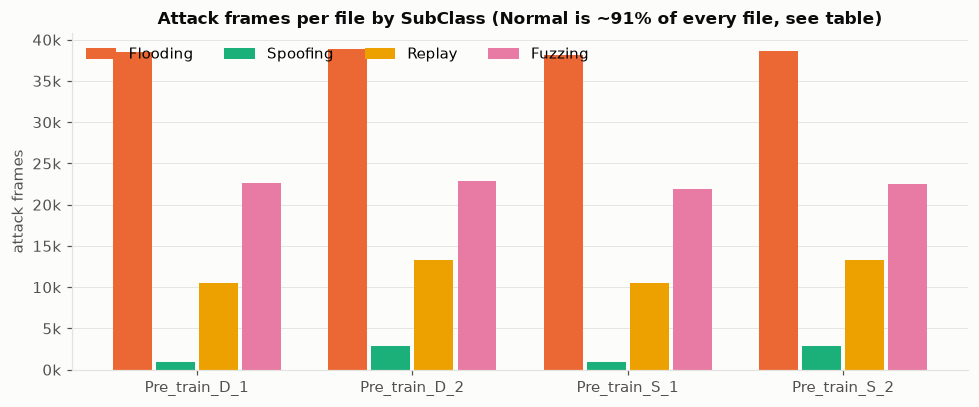

In [4]:
att_files = [f for f in counts.index if f != "ALL" and counts.loc[f, ATTACKS].sum() > 0]
x = np.arange(len(att_files))
w = 0.2
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, sc in enumerate(ATTACKS):
    vals = counts.loc[att_files, sc].to_numpy()
    bars = ax.bar(x + (k - 1.5) * w, vals, width=w - 0.02, color=SUBCLASS_COLORS[sc], label=sc)
ax.set_xticks(x, att_files)
ax.set_ylabel("attack frames")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_title("Attack frames per file by SubClass (Normal is ~91% of every file, see table)")
ax.legend(ncol=4, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**When do attacks happen inside a file?** Attack frames are grouped into *episodes* (a gap > 1 s between
consecutive attack frames of the same SubClass starts a new episode). This tells us whether attacks are
short bursts or long blocks, which matters for window size and for how many independent attack events
we actually have for validation.

,episodes,median_dur_s,max_dur_s,median_frames
subclass,,,,
Flooding,8,15.00,20.00,19142.5
Spoofing,12,9.99,14.98,494.0
Replay,8,15.00,20.00,5262.5
Fuzzing,8,15.00,20.00,11122.0


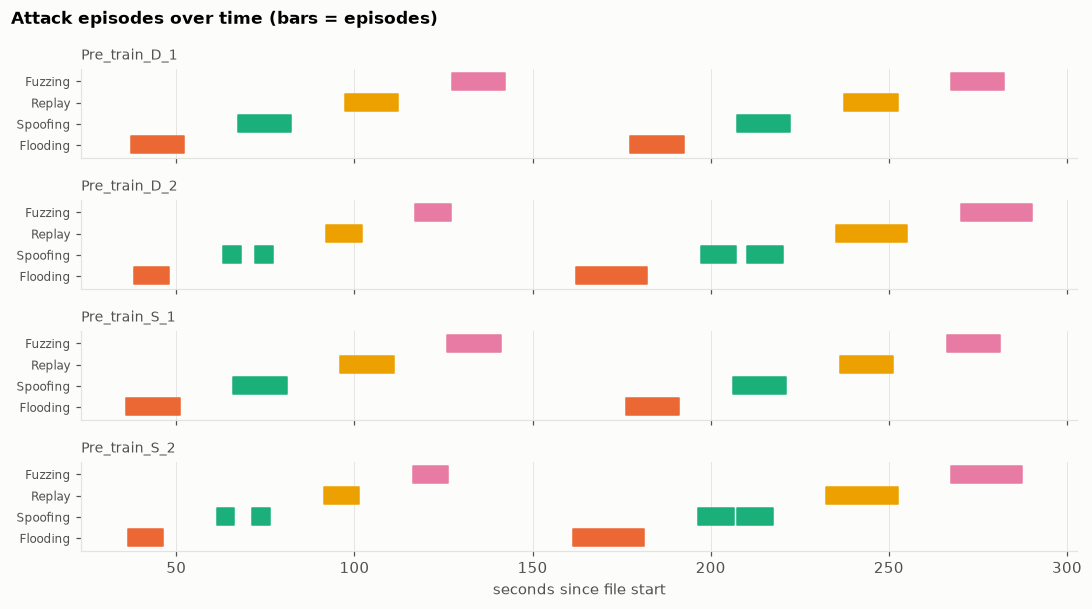

In [5]:
t0 = df.groupby("source_file", observed=True)["timestamp"].transform("min")
df["t_rel"] = df["timestamp"] - t0
att = df[df["is_attack"] == 1].copy()
att["new_ep"] = att.groupby(["source_file", "subclass"], observed=True)["t_rel"].diff().fillna(np.inf) > 1.0
att["episode"] = att.groupby(["source_file", "subclass"], observed=True)["new_ep"].cumsum()
ep = (att.groupby(["source_file", "subclass", "episode"], observed=True)
         .agg(start_s=("t_rel", "min"), end_s=("t_rel", "max"), frames=("t_rel", "size")))
ep["dur_s"] = ep["end_s"] - ep["start_s"]
ep_summary = ep.groupby(["subclass"], observed=True).agg(
    episodes=("frames", "size"), median_dur_s=("dur_s", "median"), max_dur_s=("dur_s", "max"),
    median_frames=("frames", "median"))
display(ep_summary.round(2))

fig, axes = plt.subplots(len(att_files), 1, figsize=(10, 1.25 * len(att_files) + 0.6), sharex=True)
for ax, f in zip(axes, att_files):
    for k, sc in enumerate(ATTACKS):
        e = ep.loc[f].xs(sc, level="subclass") if sc in ep.loc[f].index.get_level_values(0) else None
        if e is None: continue
        ax.broken_barh(list(zip(e["start_s"], e["dur_s"].clip(lower=0.5))), (k - 0.4, 0.8),
                       color=SUBCLASS_COLORS[sc])
    ax.set_yticks(range(len(ATTACKS)), ATTACKS, fontsize=8)
    ax.set_ylim(-0.6, len(ATTACKS) - 0.4)
    ax.set_title(f, loc="left", fontsize=9, fontweight="normal", color=INK2)
    ax.grid(axis="y", visible=False)
axes[-1].set_xlabel("seconds since file start")
fig.suptitle("Attack episodes over time (bars = episodes)", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

## 2. Top IDs
Why: the ID set defines what "known" traffic looks like. Fuzzing tends to use IDs never seen in normal
traffic (motivates `id_seen_in_training`), and flooding typically uses a high-priority (low) ID.

In [6]:
ids_per_file = pd.DataFrame({
    "unique_ids_all": df.groupby("source_file", observed=True)["arb_id"].nunique(),
    "unique_ids_normal": normal.groupby("source_file", observed=True)["arb_id"].nunique(),
    "unique_ids_attack": att.groupby("source_file", observed=True)["arb_id"].nunique(),
}).fillna(0).astype(int)
ids_per_file

,unique_ids_all,unique_ids_normal,unique_ids_attack
source_file,,,
Pre_train_D_0,73,73,0
Pre_train_D_1,81,80,81
Pre_train_D_2,81,80,81
Pre_train_S_0,73,73,0
Pre_train_S_1,81,80,81
Pre_train_S_2,81,80,81


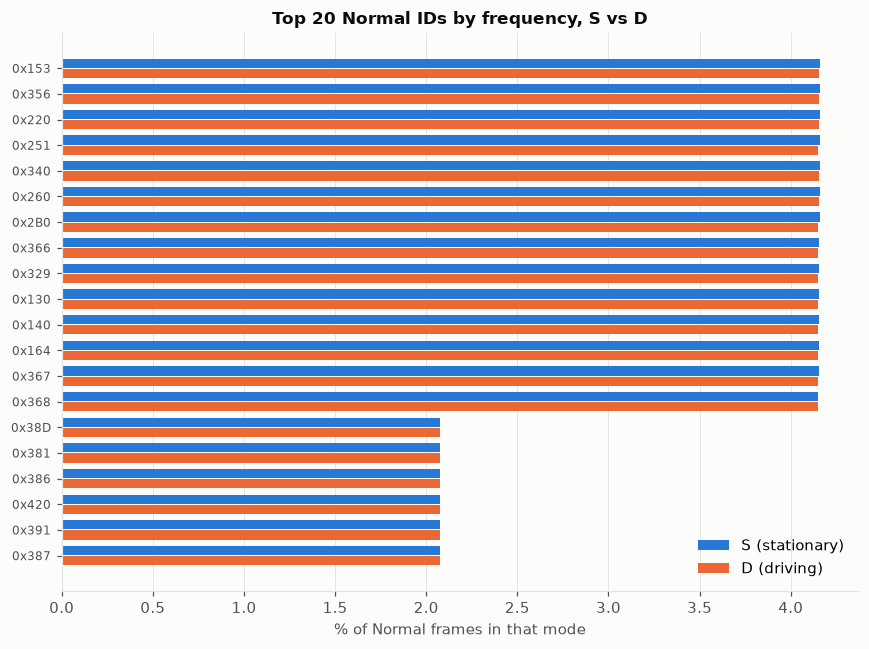

80 distinct IDs in Normal traffic; top 20 carry 70.6% of frames (avg of S and D)


In [7]:
TOP = 20
share = (normal.groupby(["mode", "arb_id"], observed=True).size()
               .groupby(level="mode", observed=True).transform(lambda s: 100 * s / s.sum())
               .unstack("mode").fillna(0))
top_ids = share.sum(axis=1).nlargest(TOP).index
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(TOP)
h = 0.4
for k, m in enumerate(["S", "D"]):
    ax.barh(y + (k - 0.5) * h, share.loc[top_ids, m], height=h - 0.04, color=MODE_COLORS[m], label=MODE_NAME[m])
ax.set_yticks(y, [hexid(i) for i in top_ids], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("% of Normal frames in that mode")
ax.set_title(f"Top {TOP} Normal IDs by frequency, S vs D")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"{len(share)} distinct IDs in Normal traffic; top {TOP} carry "
      f"{share.loc[top_ids].mean(axis=1).sum():.1f}% of frames (avg of S and D)")

In [8]:
normal_ids = set(normal["arb_id"].unique())
att["id_in_normal"] = att["arb_id"].isin(normal_ids)
id_tbl = att.groupby("subclass", observed=True).agg(
    frames=("arb_id", "size"), unique_ids=("arb_id", "nunique"),
    frames_with_id_seen_in_normal_pct=("id_in_normal", lambda s: round(100 * s.mean(), 2)),
    unseen_unique_ids=("arb_id", lambda s: int((~s.drop_duplicates().isin(normal_ids)).sum())))
top_attack_ids = (att.groupby("subclass", observed=True)["arb_id"]
                     .agg(lambda s: ", ".join(f"{hexid(i)} ({c:,})" for i, c in s.value_counts().head(4).items())))
id_tbl["top_ids (frames)"] = top_attack_ids
id_tbl

,frames,unique_ids,frames_with_id_seen_in_normal_pct,unseen_unique_ids,top_ids (frames)
subclass,,,,,
Flooding,154180,1,0.0,1,"0x000 (154,180)"
Spoofing,7756,2,100.0,0,"0x553 (3,881), 0x366 (3,875)"
Replay,47593,73,100.0,0,"0x367 (1,990), 0x251 (1,983), 0x356 (1,983), 0..."
Fuzzing,89879,80,100.0,0,"0x043 (2,030), 0x164 (2,026), 0x251 (2,022), 0..."


## 3. Per-ID inter-arrival time (to choose the window size)
Why: most CAN IDs are periodic. A window has to be long enough to contain at least one frame of most
IDs (otherwise `frame_count_last_N_ms` is mostly 0 and noisy), but short enough to react quickly to an attack.
Periods are measured on the **Normal-only** stream so injected frames don't distort them.

In [9]:
q = lambda p: (lambda s: s.quantile(p))
per_id = (normal.dropna(subset=["dt_normal"]).groupby("arb_id")["dt_normal"]
                .agg(frames="size", median="median", p5=q(0.05), p95=q(0.95), mean="mean", std="std"))
per_id["cv"] = per_id["std"] / per_id["mean"]
for c in ["median", "p5", "p95", "mean", "std"]:
    per_id[c] *= 1000  # -> ms
per_id = per_id.rename(columns={c: f"{c}_ms" for c in ["median", "p5", "p95", "mean", "std"]})
per_id.index = per_id.index.map(hexid)
print(f"{len(per_id)} IDs. Fastest and slowest 8 by median period:")
display(pd.concat([per_id.nsmallest(8, "median_ms"), per_id.nlargest(8, "median_ms")]).round(2))

NOMINAL = np.array([10, 20, 50, 100, 200, 500, 1000])
nearest = NOMINAL[np.abs(np.log(per_id["median_ms"].to_numpy()[:, None] / NOMINAL)).argmin(axis=1)]
print("IDs per nearest nominal period (ms):", dict(pd.Series(nearest).value_counts().sort_index()))
print(f"IDs with CV < 0.2 (clean periodic): {(per_id['cv'] < 0.2).sum()} / {len(per_id)}")

80 IDs. Fastest and slowest 8 by median period:


,frames,median_ms,p5_ms,p95_ms,mean_ms,std_ms,cv
arb_id,,,,,,,
0x153,140212,10.00,9.76,10.24,10.01,0.53,0.05
0x340,140149,10.00,9.71,10.29,10.01,0.53,0.05
0x356,140204,10.00,9.00,11.01,10.01,0.75,0.08
0x164,140036,10.00,9.73,10.28,10.02,0.67,0.07
0x367,140014,10.00,9.08,10.94,10.02,0.83,0.08
0x251,140165,10.00,9.74,10.26,10.01,0.56,0.06
0x368,139941,10.00,9.14,10.89,10.03,0.86,0.09
0x366,140111,10.00,8.95,11.06,10.02,0.83,0.08
0x7C4,20,3205.83,4.76,140148.59,31556.35,55924.35,1.77


IDs per nearest nominal period (ms): {10: np.int64(14), 20: np.int64(14), 50: np.int64(9), 100: np.int64(11), 200: np.int64(22), 500: np.int64(3), 1000: np.int64(7)}
IDs with CV < 0.2 (clean periodic): 67 / 80


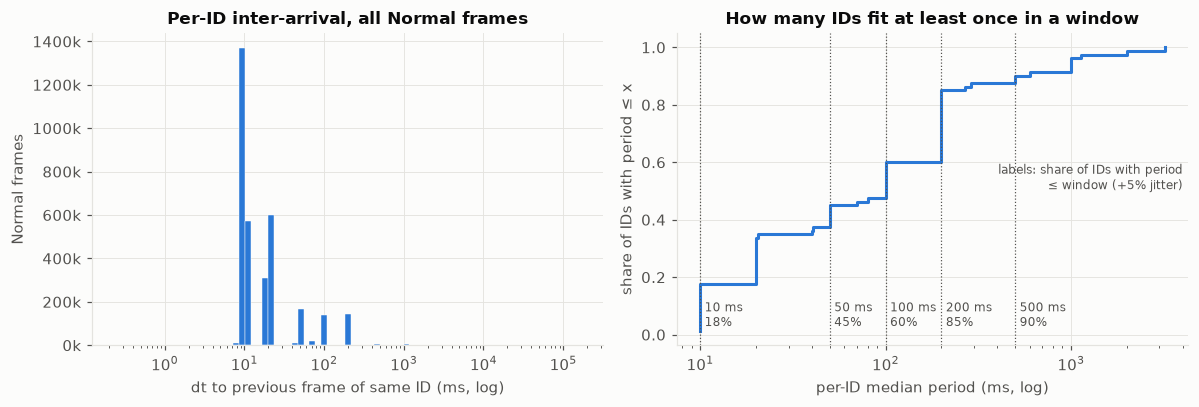

In [10]:
WINDOWS_MS = [10, 50, 100, 200, 500]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
dt_ms = normal["dt_normal"].dropna() * 1000
bins = np.logspace(np.log10(max(dt_ms.min(), 1e-3)), np.log10(dt_ms.max()), 80)
ax.hist(dt_ms, bins=bins, color=SUBCLASS_COLORS["Normal"], edgecolor="#fcfcfb", linewidth=0.3)
ax.set_xscale("log")
ax.set_xlabel("dt to previous frame of same ID (ms, log)")
ax.set_ylabel("Normal frames")
ax.set_title("Per-ID inter-arrival, all Normal frames")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))

ax = axes[1]
med = np.sort(per_id["median_ms"].to_numpy())
ax.step(med, np.arange(1, len(med) + 1) / len(med), where="post", color=SUBCLASS_COLORS["Normal"])
for wms in WINDOWS_MS:
    frac = (med <= wms * 1.05).mean()  # 5% tolerance: measured periods jitter just above nominal
    ax.axvline(wms, color=INK2, lw=0.8, ls=":")
    ax.annotate(f"{wms} ms\n{frac:.0%}", (wms, 0.03), fontsize=8, color=INK2, xytext=(3, 0),
                textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("per-ID median period (ms, log)")
ax.set_ylabel("share of IDs with period ≤ x")
ax.text(0.99, 0.5, "labels: share of IDs with period\n≤ window (+5% jitter)", transform=ax.transAxes,
        ha="right", fontsize=8, color=INK2)
ax.set_title("How many IDs fit at least once in a window")
plt.tight_layout(); plt.show()

In [11]:
# Bus-wide load per window on the Normal stream: frames and distinct IDs per tumbling window.
n_ids = normal["arb_id"].nunique()
rows = []
for wms in WINDOWS_MS:
    b = ((normal["timestamp"] - normal.groupby("source_file", observed=True)["timestamp"].transform("min"))
         // (wms / 1000)).astype(np.int64)
    g = normal.assign(b=b).groupby(["source_file", "b"], observed=True)
    frames = g.size()
    uniq = g["arb_id"].nunique()
    rows.append({"window_ms": wms, "frames_mean": frames.mean(), "frames_p5": frames.quantile(0.05),
                 "frames_p95": frames.quantile(0.95), "distinct_ids_mean": uniq.mean(),
                 "distinct_ids_pct_of_all": 100 * uniq.mean() / n_ids})
pd.DataFrame(rows).set_index("window_ms").round(1)

,frames_mean,frames_p5,frames_p95,distinct_ids_mean,distinct_ids_pct_of_all
window_ms,,,,,
10,24.0,19.0,29.0,23.9,29.9
50,120.1,111.0,129.0,44.6,55.8
100,240.3,231.0,249.0,55.6,69.6
200,480.4,477.0,492.0,67.0,83.8
500,1200.7,1190.0,1228.0,70.2,87.7


**Attack vs Normal inter-arrival (full stream).** This is what a detector sees: dt to the previous frame
of the same ID with attack frames included. A missing `dt_same_id` means the ID had not appeared
earlier in the file (typical for fuzzing with new IDs).

,frames,first_seen_pct,dt_same_id_median_ms,dt_same_id_p5_ms,dt_bus_median_ms
subclass,,,,,
Normal,3372743,0.01,10.254,9.392,0.240
Flooding,154180,0.00,0.741,0.649,0.240
Spoofing,7756,0.00,8.808,0.455,0.232
Replay,47593,0.00,6.577,0.467,0.231
Fuzzing,89879,0.03,14.861,1.046,0.219


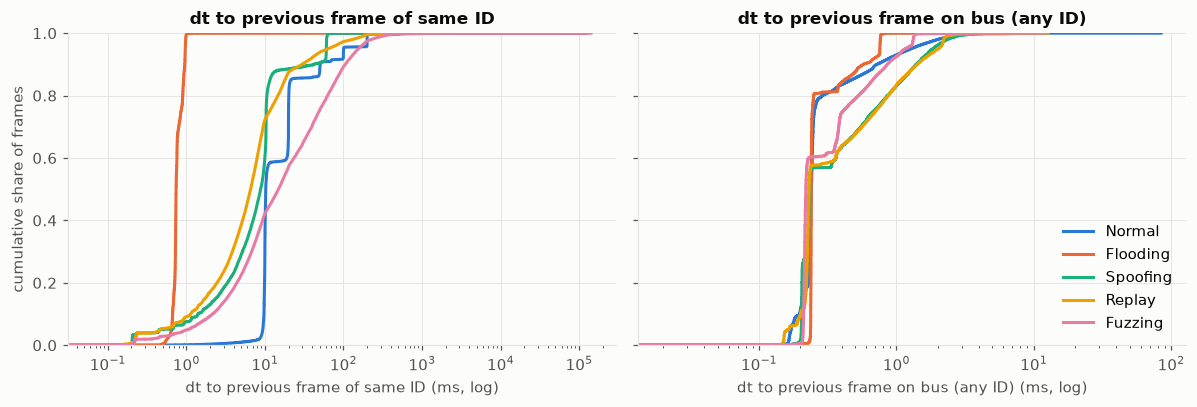

In [12]:
stats = df.groupby("subclass", observed=True).agg(
    frames=("dt_same_id", "size"),
    first_seen_pct=("dt_same_id", lambda s: round(100 * s.isna().mean(), 2)),
    dt_same_id_median_ms=("dt_same_id", lambda s: 1000 * s.median()),
    dt_same_id_p5_ms=("dt_same_id", lambda s: 1000 * s.quantile(0.05)),
    dt_bus_median_ms=("dt_bus", lambda s: 1000 * s.median()))
display(stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, title in [(axes[0], "dt_same_id", "dt to previous frame of same ID"),
                       (axes[1], "dt_bus", "dt to previous frame on bus (any ID)")]:
    for sc in SUBCLASS_CATS:
        v = df.loc[df["subclass"] == sc, col].dropna() * 1000
        v = v[v > 0]
        sns.ecdfplot(x=v, ax=ax, color=SUBCLASS_COLORS[sc], label=sc, lw=2)
    ax.set_xscale("log")
    ax.set_xlabel(f"{title} (ms, log)")
    ax.set_title(title)
axes[0].set_ylabel("cumulative share of frames")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 4. S (stationary) vs D (driving)
Why: if the two modes differ (ID set, periods, payload dynamics), a model needs the `mode` feature or
separate thresholds per mode; if they are nearly identical, one shared model is simpler.

In [13]:
rate = df.groupby(["mode", "source_file"], observed=True).agg(
    frames=("timestamp", "size"), duration_s=("t_rel", "max"))
rate["frames_per_s"] = rate["frames"] / rate["duration_s"]
nrate = normal.groupby("source_file", observed=True)["timestamp"].agg(lambda t: len(t) / (t.max() - t.min()))
rate["normal_frames_per_s"] = rate.index.get_level_values("source_file").map(nrate)
display(rate.round(1))

ids_S = set(normal.loc[normal["mode"] == "S", "arb_id"].unique())
ids_D = set(normal.loc[normal["mode"] == "D", "arb_id"].unique())
print(f"Normal IDs: S={len(ids_S)}, D={len(ids_D)}, both={len(ids_S & ids_D)}")
print("only in S:", sorted(map(hexid, ids_S - ids_D)) or "none")
print("only in D:", sorted(map(hexid, ids_D - ids_S)) or "none")

frames  duration_s  frames_per_s normal_frames_per_s
mode source_file                                                        
S    Pre_train_S_0  180686        75.3        2399.4         2399.444628
     Pre_train_S_1  799292       302.9        2638.9         2402.701538
     Pre_train_S_2  817042       308.4        2649.3         2398.446287
D    Pre_train_D_0  179346        74.7        2402.3         2402.329050
     Pre_train_D_1  806390       304.9        2645.2         2406.884801
     Pre_train_D_2  889395       337.4        2636.1         2405.317013

Normal IDs: S=80, D=80, both=80
only in S: none
only in D: none


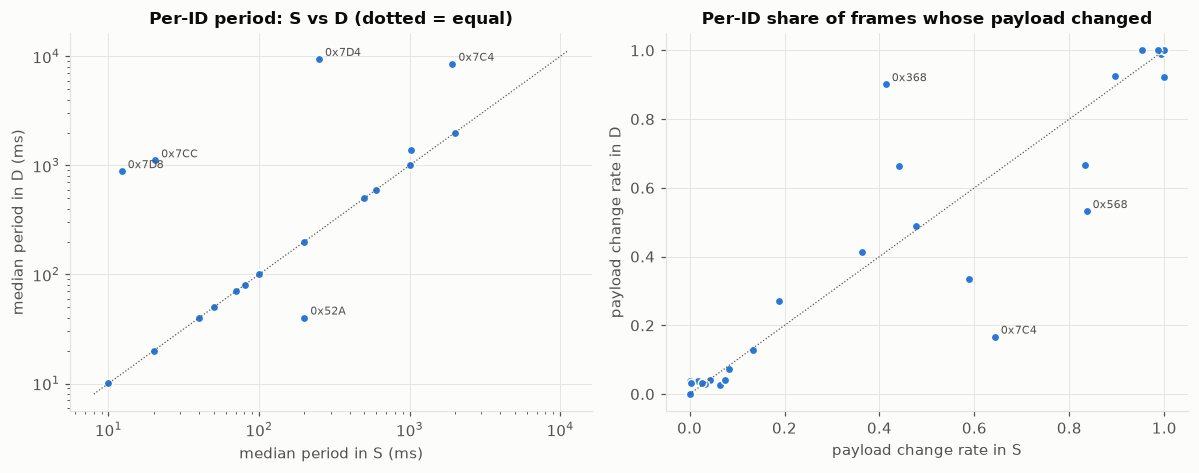

IDs with period ratio D/S outside [0.67, 1.5]: 5 / 80
IDs with (almost) constant payload: S=28, D=27 of 80
median per-ID change rate: S=0.28, D=0.22


In [14]:
# Per-ID median period and payload change rate, S vs D (Normal stream).
nn = normal.sort_values(["source_file", "arb_id", "row_idx"], kind="stable")
same_grp = (nn["source_file"].to_numpy()[1:] == nn["source_file"].to_numpy()[:-1]) & \
           (nn["arb_id"].to_numpy()[1:] == nn["arb_id"].to_numpy()[:-1])
B = nn[BYTE_COLS].to_numpy()
byte_changed = np.zeros_like(B, dtype=bool)
byte_changed[1:] = (B[1:] != B[:-1]) & same_grp[:, None]
has_prev = np.concatenate([[False], same_grp])
nn = nn.assign(payload_changed=byte_changed.any(axis=1), has_prev=has_prev)
for i, c in enumerate(BYTE_COLS):
    nn[f"chg_{i}"] = byte_changed[:, i]
nn = nn[nn["has_prev"]]

by_mode = nn.groupby(["arb_id", "mode"], observed=True).agg(
    period_ms=("dt_normal", lambda s: 1000 * s.median()), change_rate=("payload_changed", "mean")).unstack("mode")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
p = by_mode["period_ms"].dropna()
ax.scatter(p["S"], p["D"], s=30, color=SUBCLASS_COLORS["Normal"], edgecolor="#fcfcfb", linewidth=1)
lim = [p.min().min() * 0.8, p.max().max() * 1.2]
ax.plot(lim, lim, color=INK2, lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("median period in S (ms)"); ax.set_ylabel("median period in D (ms)")
ax.set_title("Per-ID period: S vs D (dotted = equal)")
ratio = p["D"] / p["S"]
for i in ratio[(ratio > 1.5) | (ratio < 1 / 1.5)].index:
    ax.annotate(hexid(i), (p.loc[i, "S"], p.loc[i, "D"]), fontsize=7, color=INK2, xytext=(4, 2), textcoords="offset points")

ax = axes[1]
c = by_mode["change_rate"].dropna()
ax.scatter(c["S"], c["D"], s=30, color=SUBCLASS_COLORS["Normal"], edgecolor="#fcfcfb", linewidth=1)
ax.plot([0, 1], [0, 1], color=INK2, lw=0.8, ls=":")
ax.set_xlabel("payload change rate in S"); ax.set_ylabel("payload change rate in D")
ax.set_title("Per-ID share of frames whose payload changed")
for i in c.index[(c["D"] - c["S"]).abs() > 0.3]:
    ax.annotate(hexid(i), (c.loc[i, "S"], c.loc[i, "D"]), fontsize=7, color=INK2, xytext=(4, 2), textcoords="offset points")
plt.tight_layout(); plt.show()

print(f"IDs with period ratio D/S outside [0.67, 1.5]: {int(((ratio > 1.5) | (ratio < 1/1.5)).sum())} / {len(ratio)}")
const = (c < 0.001)
print(f"IDs with (almost) constant payload: S={int(const['S'].sum())}, D={int(const['D'].sum())} of {len(c)}")
print(f"median per-ID change rate: S={c['S'].median():.2f}, D={c['D'].median():.2f}")

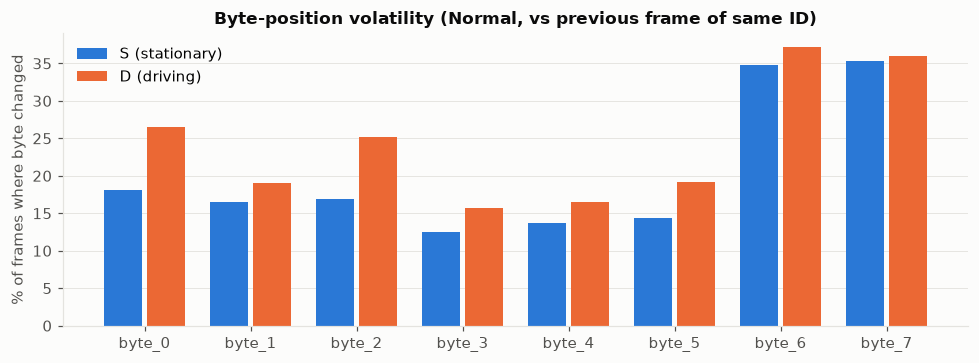

,byte_0,byte_1,byte_2,byte_3,byte_4,byte_5,byte_6,byte_7
mode,,,,,,,,
S,18.1,16.6,16.9,12.5,13.7,14.4,34.8,35.4
D,26.6,19.0,25.1,15.8,16.5,19.2,37.2,36.0


In [15]:
byte_rate = nn.groupby("mode", observed=True)[[f"chg_{i}" for i in range(8)]].mean().T
byte_rate.index = BYTE_COLS
x = np.arange(8); h = 0.4
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, m in enumerate(["S", "D"]):
    ax.bar(x + (k - 0.5) * h, 100 * byte_rate[m], width=h - 0.04, color=MODE_COLORS[m], label=MODE_NAME[m])
ax.set_xticks(x, BYTE_COLS)
ax.set_ylabel("% of frames where byte changed")
ax.set_title("Byte-position volatility (Normal, vs previous frame of same ID)")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
(100 * byte_rate).round(1).T

## 5. Takeaways

**Data quality.** All 9 files pass every integrity check (`reports/cleaning_report.md`): no nulls, no duplicates,
no DLC/payload mismatches, strictly increasing timestamps (no ties), no unknown labels. **No rows dropped.**

**Class balance (prelim_train).** 3.67M frames, 8.2% attack. `Pre_train_*_0` (75 s each) are pure Normal; the four
attack files are ~300 s with ~9% attack each. Within each subclass the counts are nearly identical across S and D.

**Attack structure.** Every attack file follows almost the same script: Flooding → Spoofing → Replay → Fuzzing,
run twice, as ~10–20 s episodes. That gives only **8 independent episodes per subclass** (12 for Spoofing) in all
of training. Phase 3 consequence: a single held-out file contains just 2 episodes per subclass, so
**leave-one-file-out CV** gives a more trustworthy estimate than one fixed val file.

**IDs.** Normal traffic uses 80 IDs (73 in the short `_0` files; the 7 missing ones are slow or diagnostic IDs).
- **Flooding** uses only `0x000`, which never appears in Normal traffic. ID-based features make Flooding trivial,
  which is exactly why the ID-inclusive vs. pure-behavioural ablation matters.
- **Fuzzing uses only *known* IDs** (100% of its frames have an ID seen in Normal traffic). In this dataset it randomises
  payloads of existing IDs, so `id_seen_in_training` will **not** catch Fuzzing. Payload-based features
  (`payload_seen_before`, per-ID byte behaviour) and `dt_same_id` have to carry it.
- **Spoofing** targets 2 IDs (`0x553`, `0x366`); **Replay** re-sends frames of 73 known IDs.

**Timing (window size).** 67 of 80 IDs are cleanly periodic (CV < 0.2), with nominal periods of
10 ms (14 IDs), 20 ms (14), 50 ms (9), 100 ms (11), 200 ms (22), 500 ms (3) and 1000 ms (7). The slow, irregular
IDs are mostly `0x7xx` diagnostics. Normal bus load is very stable at ~2,400 frames/s.
- 100 ms window: 240 frames (p5–p95 231–249) and contains every ID with period ≤ 100 ms (60% of IDs).
- 200 ms window: 480 frames and covers ~85% of IDs.
- Flooding injects a `0x000` frame every ~0.74 ms (~135 extra frames per 100 ms), far outside the ±9 frame normal spread.
- **Candidate: 100 ms** for `frame_count_last_N_ms`, with 50 ms / 200 ms as the Phase 3 ablation.
  Per-ID features (`dt_same_id`) need no window: the Normal median is 10.25 ms vs 0.74 ms for Flooding, and Spoofing
  and Replay shift the per-ID dt left (6.6–8.8 ms median, p5 < 0.5 ms) because injected frames interleave with real ones.

**S vs D.** The two modes are much closer than expected at the bus level: the same 80 IDs, the same ~2,400 Normal frames/s,
and 75/80 IDs with the same period (the exceptions are diagnostic `0x7xx` IDs and `0x52A`). D has somewhat more payload
volatility (bytes 0 and 2 change in 27% / 25% of frames vs 18% / 17% in S). One shared model with `mode` as a (probably weak)
feature looks reasonable; per-mode thresholds are worth checking in Phase 3.

**Not looked at:** `Pre_submit_*` and `Fin_*` distributions (held-out test sets).